# Caco-2: SPIRE validation

**Notebook type:** experiment. Compare U/R training, four AC constraints and WISP
on the full eligible population; illustrate atom maps and descriptor reconstruction
with three selected validation MMPs.
Source: [TDC_Caco2_Wang_4259569](https://tdcommons.ai/single_pred_tasks/adme/#caco-2-cell-effective-permeability-wang-et-al). The supplied target is **Caco-2 log10(Papp / cm s⁻¹)**;
no additional logarithm, offset, or sign reversal is applied.

Use the existing two-layer GCN (32 hidden units), frozen singleton CheMeleon
representations, and 100 epochs per condition. This is one random 80/20 split,
not the TDC scaffold benchmark or evidence of a transferable chemical mechanism.
The selected MMPs use the same seven CREST/AIMNet2-NSE/OpenFF descriptors as the paper, supplied as computed input tables.


**Training:** 100 epochs per U/R condition. Local paths in this record are displayed relative to the repository root.


In [1]:
LOCAL_PROJECT_ROOT = "."
EPOCHS = 100
SEED = 42
RUN_MODE = "train"
RUN_NAME = "caco2_transfer"
CHECKPOINT_PATH = "checkpoints/chemeleon_mp.pt"
CACHE_DIRECTORY = "test_sample/output/caco2_transfer/representations"


In [2]:
# Parameters
LOCAL_PROJECT_ROOT = "."
RUN_MODE = "train"
RUN_NAME = "caco2_transfer"


## 1. Runtime and public API

In [3]:
from pathlib import Path
import os
import sys
import json
from IPython.display import display

# Use the declared repository root in both Colab and local execution.
try:
    import google.colab
except ModuleNotFoundError as exc:
    if exc.name not in {"google", "google.colab"}:
        raise
    IS_COLAB = False
else:
    IS_COLAB = True
ROOT = Path(os.environ.get("XAI_CHEM_ROOT", LOCAL_PROJECT_ROOT)).expanduser().resolve()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print({"runtime": "colab" if IS_COLAB else "local", "root": str(ROOT), "python": sys.executable})

# Numerical tables, chemistry figures, and explicit CPU execution.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
torch.set_num_threads(2)
%matplotlib inline
from xai_chem.transfer import build_regression_mmp, load_paper_atom_descriptors, PAPER_DESCRIPTORS
from urllib.request import Request, urlopen
from xai_chem.graphs import build_graphs
from xai_chem.representations import load_molecule_inputs_with_provenance, CheMeleonSingletonProvider, build_or_reuse_cache
from xai_chem.dataset import DataConfig, CacheBackedGraphDataset
from xai_chem.config import TrainingConfig
from xai_chem.training import run_fold_training
from xai_chem.results import load_completed_fold_results, check_additivity, assert_completed_result_matches_config

from rdkit import Chem


{'runtime': 'local', 'root': '.', 'python': 'python (verified local environment)'}


## 2. Acquire the source and declare the population/split

Download the source unchanged into this run's output directory. Its origin and
terms are documented under `test_sample/input_data/`. Filtering uses chemistry,
not target values. Keep the first canonical-SMILES occurrence before splitting;
retain excluded and duplicate rows for inspection. Use all eligible molecules.


In [4]:
run_root = ROOT / "test_sample/output" / RUN_NAME
run_root.mkdir(parents=True, exist_ok=True)
source_path = run_root / "input_data/upstream.csv"
SOURCE_URL = "https://dataverse.harvard.edu/api/access/datafile/4259569?format=original"
RUN_DOWNLOAD = not source_path.exists()
print({"download": RUN_DOWNLOAD, "source_url": SOURCE_URL, "input_path": str(source_path)})
if RUN_DOWNLOAD:
    source_path.parent.mkdir(parents=True, exist_ok=True)
    # Dataverse requires a browser-compatible user agent; source bytes are unchanged.
    request = Request(SOURCE_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=60) as response:
        source_path.write_bytes(response.read())
raw = pd.read_csv(source_path)
raw.insert(0, "source_row", np.arange(len(raw)))
source_count = len(raw)
molecules = raw["Drug"].map(Chem.MolFromSmiles)
# Preserve the existing training population and row identities.
# Physicochemical reconstruction uses only the supplied Sage-compatible endpoints.
allowed_elements = {1, 5, 6, 7, 8, 9, 14, 15, 16, 17, 35, 53}
valid = molecules.map(lambda mol: mol is not None and len(Chem.GetMolFrags(mol)) == 1
                      and all(atom.GetAtomicNum() in allowed_elements for atom in mol.GetAtoms()))
curated = raw.loc[valid].copy()
curated["Smiles"] = molecules.loc[valid].map(lambda mol: Chem.MolToSmiles(mol, isomericSmiles=True))
duplicates = curated.duplicated("Smiles", keep="first")
curated.loc[duplicates].to_csv(run_root / "duplicate_structures.csv", index=False)
excluded = raw.loc[~valid].copy()
excluded["exclusion_reason"] = molecules.loc[~valid].map(
    lambda mol: "invalid_smiles" if mol is None else "disconnected_structure" if len(Chem.GetMolFrags(mol)) != 1
    else "unsupported_elements:" + ",".join(sorted({a.GetSymbol() for a in mol.GetAtoms() if a.GetAtomicNum() not in allowed_elements})))
excluded.to_csv(run_root / "excluded_structures.csv", index=False)
frame = curated.loc[~duplicates].reset_index(drop=True)
frame["log_papp"] = frame["Y"]
frame["name"] = frame["Drug_ID"]
frame["cid"] = "caco2_" + frame["source_row"].astype(str)
frame.insert(0, "index", np.arange(1, len(frame) + 1))
dataset_path = run_root / "caco2.csv"
frame.to_csv(dataset_path, index=False)
permutation = np.random.default_rng(SEED).permutation(len(frame))
fold_ids = np.empty(len(frame), dtype=int)
fold_ids[permutation] = np.arange(len(frame)) % 5
fold_table = pd.DataFrame({"index": frame["index"], "fold": fold_ids})
fold_path = run_root / "folds.csv"
fold_table.to_csv(fold_path, index=False)
print({"source_rows": source_count, "endpoint_rows": len(raw),
       "chemistry_exclusions": int((~valid).sum()), "duplicate_structures": int(duplicates.sum()),
       "eligible": len(frame), "seed": SEED, "validation_fold": 0,
       "target_units": "log10(Papp / cm s⁻¹)", "fold_counts": fold_table["fold"].value_counts().sort_index().to_dict()})


{'download': False, 'source_url': 'https://dataverse.harvard.edu/api/access/datafile/4259569?format=original', 'input_path': './test_sample/output/caco2_transfer/input_data/upstream.csv'}


{'source_rows': 910, 'endpoint_rows': 910, 'chemistry_exclusions': 9, 'duplicate_structures': 4, 'eligible': 897, 'seed': 42, 'validation_fold': 0, 'target_units': 'log10(Papp / cm s⁻¹)', 'fold_counts': {0: 180, 1: 180, 2: 179, 3: 179, 4: 179}}


## 3. Build heavy-atom topology with the declared target


In [5]:
graph_root = run_root / "graphs"
RUN_GRAPH_BUILD = not graph_root.exists()
print({"run_graph_build": RUN_GRAPH_BUILD})
if RUN_GRAPH_BUILD:
    build_graphs(dataset_path, graph_root, target_column="log_papp")
loaded = load_molecule_inputs_with_provenance(dataset_path, graph_root, dataset_id="TDC_Caco2_Wang_4259569")
print({"included": len(loaded.molecules), "excluded": len(loaded.exclusions),
       "atoms": sum(len(mol.atomic_numbers) for mol in loaded.molecules)})


{'run_graph_build': False}


{'included': 897, 'excluded': 0, 'atoms': 26393}


## 4. Extract the actual pretrained atom representations

Each molecule is encoded alone. The same raw CheMeleon weights are used for both training conditions.

In [6]:
provider = CheMeleonSingletonProvider(checkpoint_path=ROOT / CHECKPOINT_PATH, device="cpu")
bundle = build_or_reuse_cache(ROOT / CACHE_DIRECTORY, provider, loaded.molecules,
                             input_provenance=loaded.input_provenance, provider_scoped_root=True)
print({"shape": bundle.values.shape, "extraction_mode": bundle.metadata["extraction_mode"],
       "provider": bundle.metadata["provider"]["provider"]})


{'shape': (26393, 2048), 'extraction_mode': 'singleton', 'provider': 'chemeleon'}


## 5. Construct corrected single-cut MMPs

Reuse the original cut SMARTS and automorphism-aware mapping. Pairs are grouped
within this dataset.
Inherited filters require Morgan similarity ≥ 0.1 and |Δtarget| ≥ 0.1 in
log10(Papp / cm s⁻¹). Thus WISP describes this filtered MMP population, not all molecular pairs.
Training uses only train/train pairs. Validation/validation pairs are evaluation only.


In [7]:
mmp_path = run_root / "mmp.csv"
if not mmp_path.exists():
    mmp = build_regression_mmp(frame, graph_root, mmp_path,
                               target_column="log_papp", dataset_group="caco2_dataset_group")
else:
    mmp = pd.read_csv(mmp_path)
train_rows = set(np.flatnonzero(fold_ids != 0))
validation_rows = set(np.flatnonzero(fold_ids == 0))
train_pairs = mmp["i_id"].isin(train_rows) & mmp["j_id"].isin(train_rows)
validation_pairs = mmp["i_id"].isin(validation_rows) & mmp["j_id"].isin(validation_rows)
print({"total_pairs": len(mmp), "training_pairs": int(train_pairs.sum()),
       "validation_pairs": int(validation_pairs.sum()), "dy_units": "log10(Papp / cm s⁻¹)"})


{'total_pairs': 631, 'training_pairs': 392, 'validation_pairs': 35, 'dy_units': 'log10(Papp / cm s⁻¹)'}


## 6. Fix matched U/R conditions before training

Use identical architecture, initialization, training rows, train-only target scaling,
optimizer, and epoch budget. Keep the final epoch without validation selection.
U disables auxiliary outer weights; R uses the existing weights unchanged.
Frequent-fragment positivity is a model allocation hypothesis in standardized
target space; it is not a universal chemical sign constraint for this endpoint.

Training requires deterministic Torch kernels, including CPU indexed-gradient
accumulation. Repeatability is scoped to the same software/hardware; runtime
policy and thread count are recorded with each model.


In [8]:
data_config = DataConfig(dataset_csv=dataset_path, graph_root=graph_root, fold_csv=fold_path,
                         representation_cache=ROOT / CACHE_DIRECTORY, target_column="log_papp",
                         graph_file_template=f"graph_{{molecule_id:0{max(3, len(str(len(frame))))}d}}.pt")
raw_dataset = CacheBackedGraphDataset(data_config, validate_all=True)
common = dict(data=data_config, mmp_csv=mmp_path, fragment_cache=None, device="cpu",
              epochs=EPOCHS, seed=SEED, validation_fold=0, expected_train_rows=len(train_rows),
              expected_retained_mmp_pairs=int(train_pairs.sum()), expected_mmp_source_pairs=len(mmp),
              expected_mmp_symmetry_ambiguous_pairs=int((mmp["core_pair_automorphism_candidate_count"] > 1).sum()),
              expected_mmp_max_automorphism_candidates=int(mmp["core_pair_automorphism_candidate_count"].max()),
              backbone_name="gcn", hidden_dim=32, num_layers=2, use_edge_features=False,
              heads=None, dropout=0.0, backbone_normalization="layernorm", readout_hidden_dim=32,
              readout_num_layers=2, output_head_init_std=0.001, optimization_mode="full_objective",
              checkpoint_selection="fixed_final_epoch", early_stopping_patience=None,
              learning_rate=0.002, weight_decay=0.0001, mmp_pair_batch_size=2048,
              supervised_batch_size=128, mmp_core_weight=3.0, mmp_difference_weight=1.0,
              fragment_positive_weight=1.0, fragment_consistency_weight=1.0)
configs = {label: TrainingConfig(output_dir=run_root / label, mmp_weight=pair_weight,
                                fragment_frequency_weight=fragment_weight, **common)
           for label, pair_weight, fragment_weight in [("U", 0.0, 0.0), ("R", 5.0, 1.0)]}
print({"backbone": common["backbone_name"], "hidden_dim": common["hidden_dim"],
       "epochs": EPOCHS, "seed": SEED, "checkpoint_selection": common["checkpoint_selection"],
       "mmp_outer_weights": {label: config.mmp_weight for label, config in configs.items()},
       "fragment_outer_weights": {label: config.fragment_frequency_weight for label, config in configs.items()}})

# Inspect the graph/SMILES atom correspondence used by the model and figures.
example_graph = raw_dataset[0]
print(example_graph)
pd.DataFrame({"smiles_atom_index": np.arange(example_graph.num_nodes),
              "graph_atom_index": example_graph.smiles_to_graph_atom_index.numpy()}).to_csv(
                  run_root / "example_atom_mapping.csv", index=False)


{'backbone': 'gcn', 'hidden_dim': 32, 'epochs': 100, 'seed': 42, 'checkpoint_selection': 'fixed_final_epoch', 'mmp_outer_weights': {'U': 0.0, 'R': 5.0}, 'fragment_outer_weights': {'U': 0.0, 'R': 1.0}}
Data(x=[21, 2048], edge_index=[2, 46], edge_attr=[46, 6], atomic_numbers=[21], smiles_to_graph_atom_index=[21], y_raw=[1], smiles='Oc1cc(O)c2c(c1)OC(c1ccc(O)c(O)c1)C(O)C2', idx=1, index='caco2_0', sample_id='1', graph_idx=0, y=[1], cache_idx=0)


## 7. Train both models through the published training engine

In [9]:
completed = {}
def print_progress(row):
    if int(row["epoch"]) == 1 or int(row["epoch"]) % 20 == 0:
        print({key: row[key] for key in ("epoch", "optimization_total", "training_rmse_raw", "validation_rmse_raw")}, flush=True)

for label, config in configs.items():
    print(f"Condition {label}", flush=True)
    if RUN_MODE == "train":
        run_fold_training(config, raw_dataset=raw_dataset, epoch_observer=print_progress)
    elif RUN_MODE != "reuse":
        raise ValueError("RUN_MODE must be train or reuse")
    completed[label] = load_completed_fold_results(config.output_dir)
    assert_completed_result_matches_config(completed[label], config)
    print({"condition": label, "epochs_saved": len(completed[label].history)})
    print({"condition": label, "trained_runtime": completed[label].provenance["runtime"]})


Condition U


{'epoch': 1, 'optimization_total': 1.010177493095398, 'training_rmse_raw': 0.7923124632378366, 'validation_rmse_raw': 0.7709723209825512}


{'epoch': 20, 'optimization_total': 0.24148866534233093, 'training_rmse_raw': 0.37509070729892935, 'validation_rmse_raw': 0.44844896454727173}


{'epoch': 40, 'optimization_total': 0.08918286859989166, 'training_rmse_raw': 0.2272731553420457, 'validation_rmse_raw': 0.3976594396437033}


{'epoch': 60, 'optimization_total': 0.04570857062935829, 'training_rmse_raw': 0.17354957894159057, 'validation_rmse_raw': 0.3857557849660399}


...

{'epoch': 40, 'optimization_total': 0.35130709409713745, 'training_rmse_raw': 0.3281971647742476, 'validation_rmse_raw': 0.44435890892930174}


{'epoch': 60, 'optimization_total': 0.23493386805057526, 'training_rmse_raw': 0.2725688214845011, 'validation_rmse_raw': 0.43801408604502684}


{'epoch': 80, 'optimization_total': 0.1513940989971161, 'training_rmse_raw': 0.18250593580756688, 'validation_rmse_raw': 0.395922107111291}


{'epoch': 100, 'optimization_total': 0.12479348480701447, 'training_rmse_raw': 0.17448261895726133, 'validation_rmse_raw': 0.40058843796952603}


{'condition': 'R', 'epochs_saved': 100}
{'condition': 'R', 'trained_runtime': {'cudnn_benchmark': False, 'cudnn_deterministic': True, 'data_loader_num_workers': 0, 'device': {'resolved': 'cpu'}, 'packages': {'numpy': '2.0.2', 'pandas': '2.3.3', 'rdkit': '2026.3.1', 'torch': '2.12.0', 'torch-geometric': '2.8.0'}, 'python': '3.12.5', 'seed': 42, 'torch_deterministic_algorithms': True, 'torch_num_threads': 2}}


## 8. Measure all four constraints on matched atom and pair populations

In [10]:
from xai_chem.transfer import measure_ac_constraints

constraint_rows = []
for label, result in completed.items():
    for split in ("train", "validation"):
        constraint_rows.append({"condition": label, **measure_ac_constraints(result, raw_dataset, mmp_path, split=split)})
constraints = pd.DataFrame(constraint_rows)
display(constraints)
constraints.to_csv(run_root / "ac_constraints.csv", index=False)
train_constraints = constraints.query("split == 'train'").set_index("condition")
ratios = train_constraints.loc["R", ["core", "difference", "positive", "consistency"]] / train_constraints.loc["U", ["core", "difference", "positive", "consistency"]]
print({"training_constraint_ratios_R_div_U": ratios.astype(float).round(4).to_dict()})


,condition,split,mmp_pairs,core,difference,positive,consistency
0,U,train,392,0.002753,0.058701,8.495974,2.999124
1,U,validation,35,0.000540,0.050989,8.389372,3.106620
2,R,train,392,0.000846,0.055941,0.000410,0.009603
3,R,validation,35,0.000341,0.051274,0.032646,0.127033


{'training_constraint_ratios_R_div_U': {'core': 0.3072, 'difference': 0.953, 'positive': 0.0, 'consistency': 0.0032}}


The ratios compare raw loss components evaluated with identical definitions. Values below one show that the regularized model better satisfies that measured constraint. Validation is reported separately and is not used to tune these weights.

## 9. Inspect predictive fit, additivity, and learning curves

Use the frozen project Y–Y style (prediction on x; experiment on y) and
raw/light plus smoothed/dark scaled-MSE curves. The selected checkpoint is explicit.


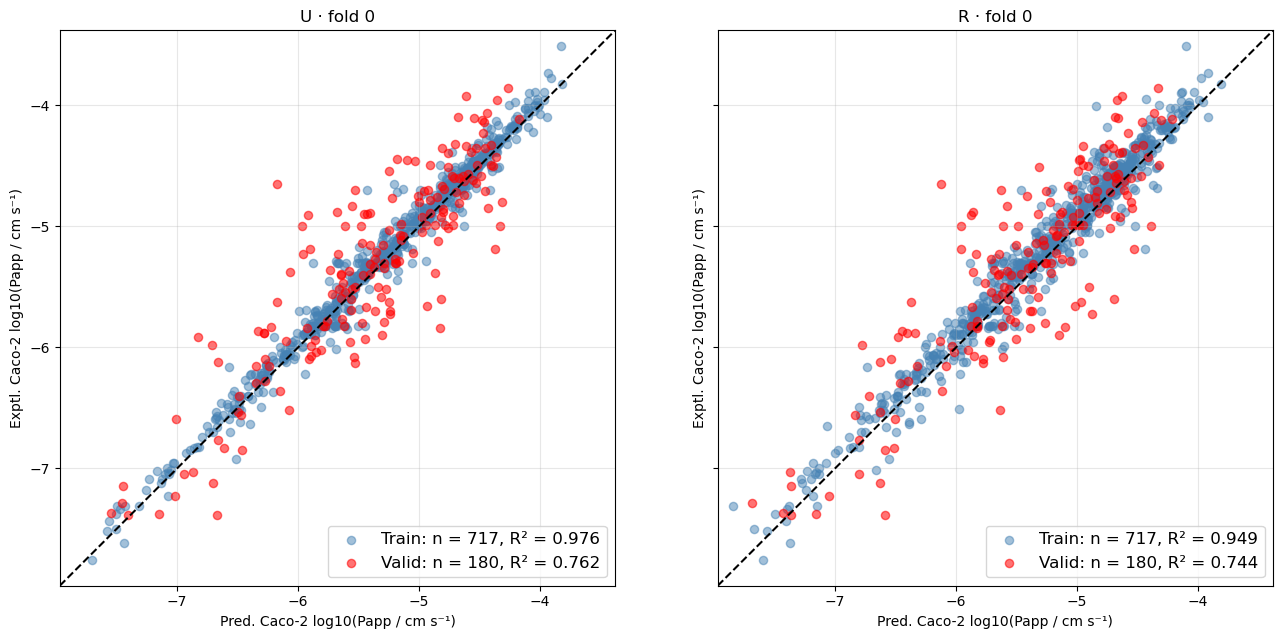

,condition,split,n,r2_score_raw,rmse_raw
0,U,train,717,0.9762,0.1187
1,U,validation,180,0.7625,0.3860
2,R,train,717,0.9486,0.1745
3,R,validation,180,0.7442,0.4006


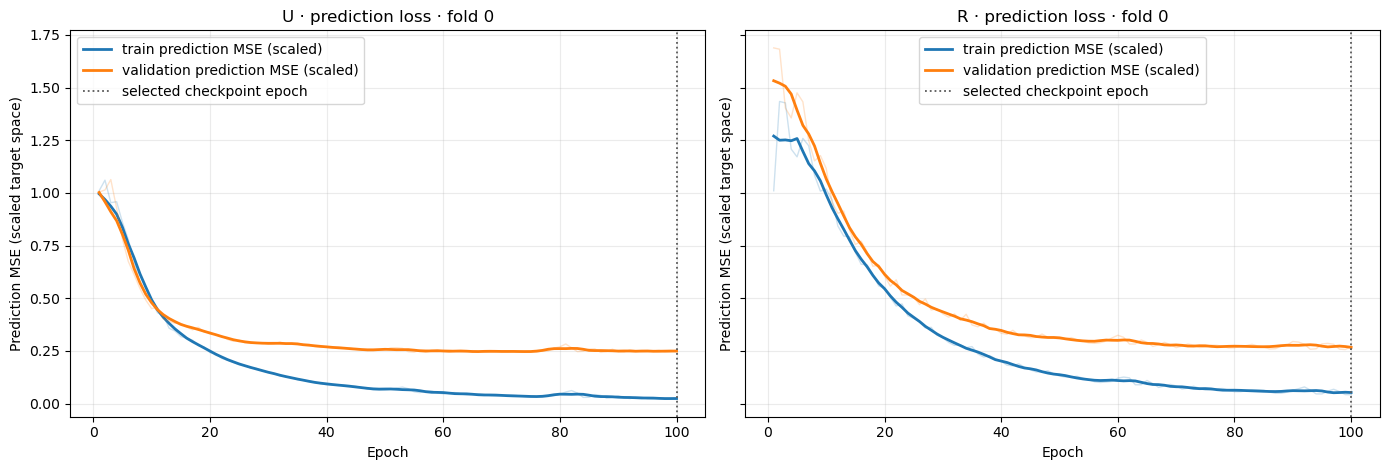

{'additivity_passed': {'U': True, 'R': True}}


In [11]:
TARGET_LABEL = "Caco-2 log10(Papp / cm s⁻¹)"
TARGET_UNITS = "log10(Papp / cm s⁻¹)"
from xai_chem.plotting import (
    plot_train_validation_yy, plot_prediction_loss_curves, save_publication_figure,
)
# Compare U/R within each figure type; keep the established train/validation style.
all_predictions = pd.concat([result.predictions for result in completed.values()])
span = all_predictions[["target_raw", "prediction_raw"]].to_numpy()
padding = 0.03 * max(float(span.max() - span.min()), 1.0)
limits = (float(span.min() - padding), float(span.max() + padding))
figure, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharex=True, sharey=True)
summary_rows, additivity_passed = [], {}
for axis, label in zip(axes, ("U", "R")):
    result = completed[label]
    _, scores = plot_train_validation_yy(result, run_name=label, limits=limits,
                                         target_label=TARGET_LABEL, axis=axis)
    axis.set_title(f"{label} · fold 0")
    summary_rows.append(scores.assign(condition=label))
    audit = check_additivity(result.predictions, result.atom_contributions)
    additivity_passed[label] = bool(audit["scaled_pass"].all() and audit["raw_pass"].all())
    if not additivity_passed[label]:
        raise ValueError(f"Additivity failed for {label}")
save_publication_figure(figure, run_root / "vis" / "UR_yy.png")
display(figure); plt.close(figure)
summary = pd.concat(summary_rows, ignore_index=True)
display(summary[["condition", "split", "n", "r2_score_raw", "rmse_raw"]].round(4))
summary.to_csv(run_root / "prediction_metrics.csv", index=False)

figure, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True, sharey=True)
for axis, label in zip(axes, ("U", "R")):
    plot_prediction_loss_curves(completed[label], axis=axis)
    axis.set_title(f"{label} · prediction loss · fold 0")
figure.tight_layout()
save_publication_figure(figure, run_root / "vis" / "UR_learning.png")
display(figure); plt.close(figure)
print({"additivity_passed": additivity_passed})


## 10. Three large experimental contrasts; R-only reconstruction

Select the three largest |experimental B−A| gaps among validation/validation pairs,
with distinct transformations and pair ID as the tie-breaker, among endpoints covered by the supplied paper-descriptor table. This is a deliberately
selected illustration, not a representative performance sample. Fit the paper's seven physicochemical descriptors with Ridge alpha=1 to R changed-region ACs only. Precomputed descriptors cover the selected MMP endpoints; they do not alter model inputs or training.


In [12]:
from xai_chem.reconstruction import fit_pair
# Select distinct transformations by observed target gap, never by AC/fidelity.
# These deliberately strong contrasts illustrate the method, not average performance.
descriptors = load_paper_atom_descriptors(ROOT / "test_sample/input_data/caco2/paper_atom_descriptors.csv", frame)
# Restrict reconstruction examples to endpoints with verified paper descriptors.
# Mayr excludes unassignable Sage chemistry before ranking by measured target gap.
descriptor_rows = set(descriptors["graph_id"])
selected_pairs = (mmp.loc[validation_pairs & mmp["i_id"].isin(descriptor_rows) & mmp["j_id"].isin(descriptor_rows)]
    .assign(abs_target_difference=lambda rows: (rows["target_j"] - rows["target_i"]).abs())
    .sort_values(["abs_target_difference", "pair_id"], ascending=[False, True], kind="stable")
    .drop_duplicates("mmp_transform").head(3))
selected_pairs.to_csv(run_root / "selected_mmp_examples.csv", index=False)
teacher = completed["R"].atom_contributions.rename(columns={
    "source_row_index": "graph_id", "smiles_atom_index": "atom_idx",
    "atom_contribution_raw": "atom_contribution",
})
atom_table = descriptors.merge(teacher[["graph_id", "atom_idx", "atom_contribution"]],
                               on=["graph_id", "atom_idx"], validate="one_to_one")
fitted_pairs, fits = {}, []
for pair in selected_pairs.itertuples(index=False):
    context = f"R_pair_{pair.pair_id}"
    pieces = []
    for graph_id, indices in [(pair.i_id, json.loads(pair.diff_i_json)),
                              (pair.j_id, json.loads(pair.diff_j_json))]:
        pieces.append(atom_table[atom_table["graph_id"].eq(graph_id)
                     & atom_table["atom_idx"].isin(indices)].assign(context_id=context))
    inputs = pd.concat(pieces, ignore_index=True)
    key = pd.Series({"context_id": context, "pair_id": pair.pair_id,
                     "molecule_a": frame.iloc[pair.i_id]["cid"],
                     "molecule_b": frame.iloc[pair.j_id]["cid"]})
    fitted = fit_pair(key, inputs, alpha=1.0, features=PAPER_DESCRIPTORS)
    fitted.atoms.to_csv(run_root / f"R_pair_{pair.pair_id}_atom_reconstruction.csv", index=False)
    fitted.concept_totals.to_csv(run_root / f"R_pair_{pair.pair_id}_descriptor_effects.csv", index=False)
    fits.append(fitted.metrics.assign(condition="R"))
    fitted_pairs[pair.pair_id] = fitted
reconstruction = pd.concat(fits, ignore_index=True)
reconstruction.to_csv(run_root / "descriptor_reconstruction.csv", index=False)
# One compact table replaces repeated fit, coefficient, and atom tables.
pair_summary = selected_pairs[["pair_id", "target_i", "target_j", "abs_target_difference"]].merge(
    reconstruction.loc[reconstruction["level"].eq("A+B diff-region atoms"), ["pair_id", "n", "r2"]],
    on="pair_id", validate="one_to_one")
display(pair_summary.rename(columns={"r2": "R_in_sample_atom_R2"}).round(4))


,pair_id,target_i,target_j,abs_target_difference,n,R_in_sample_atom_R2
0,68,-6.1525,-4.8797,1.2728,21,0.7097
1,74,-6.0250,-4.8797,1.1453,19,0.8455
2,866,-4.7500,-5.8393,1.0893,12,0.7691


## 11. Matched MMP maps: U/R rows, A/B columns

Three 2×2 panels use one raw AC scale and no atom indices. Titles retain predictions,
observations, errors and target units. Detailed atom values, affine baselines and
saturation audits are saved to CSV instead of repeated inline tables.


{'shared_raw_ac_symmetric_limit': 0.1805014610290527, 'raw_ac_units': 'log10(Papp / cm s⁻¹)', 'atom_indices_displayed': False}


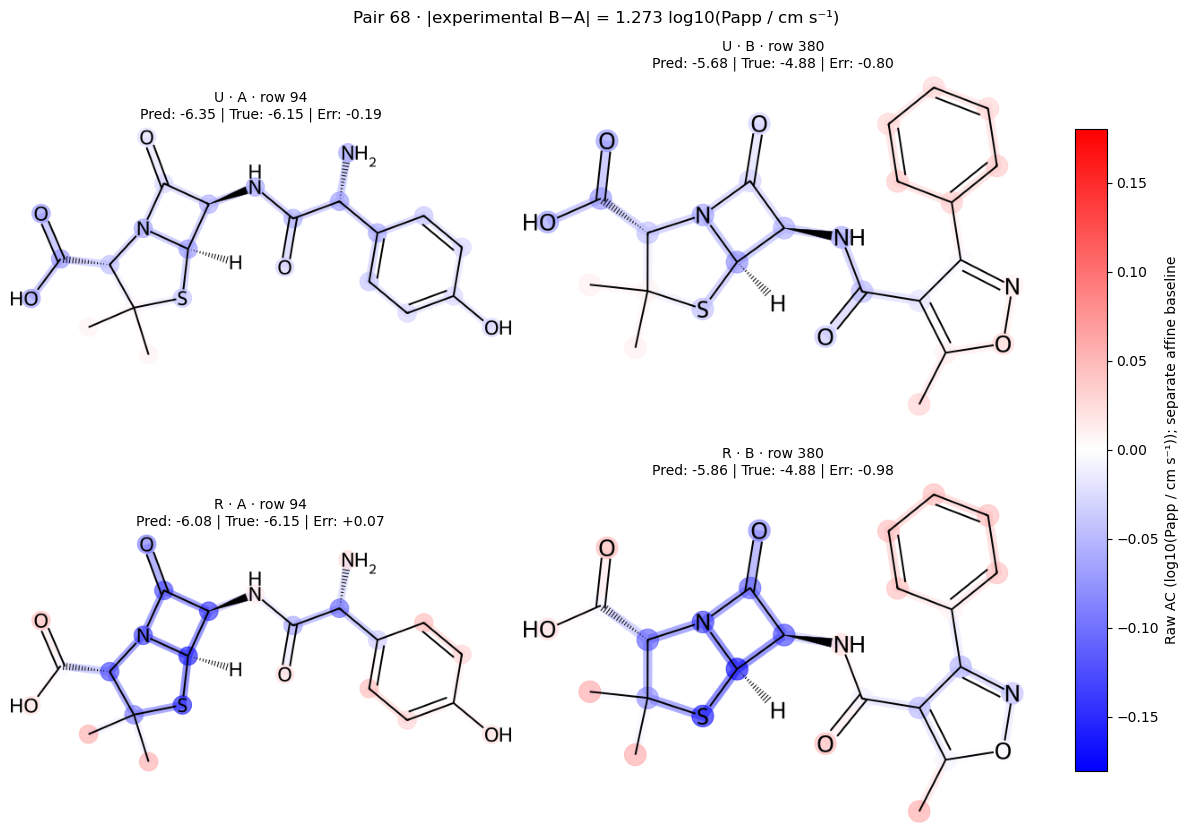

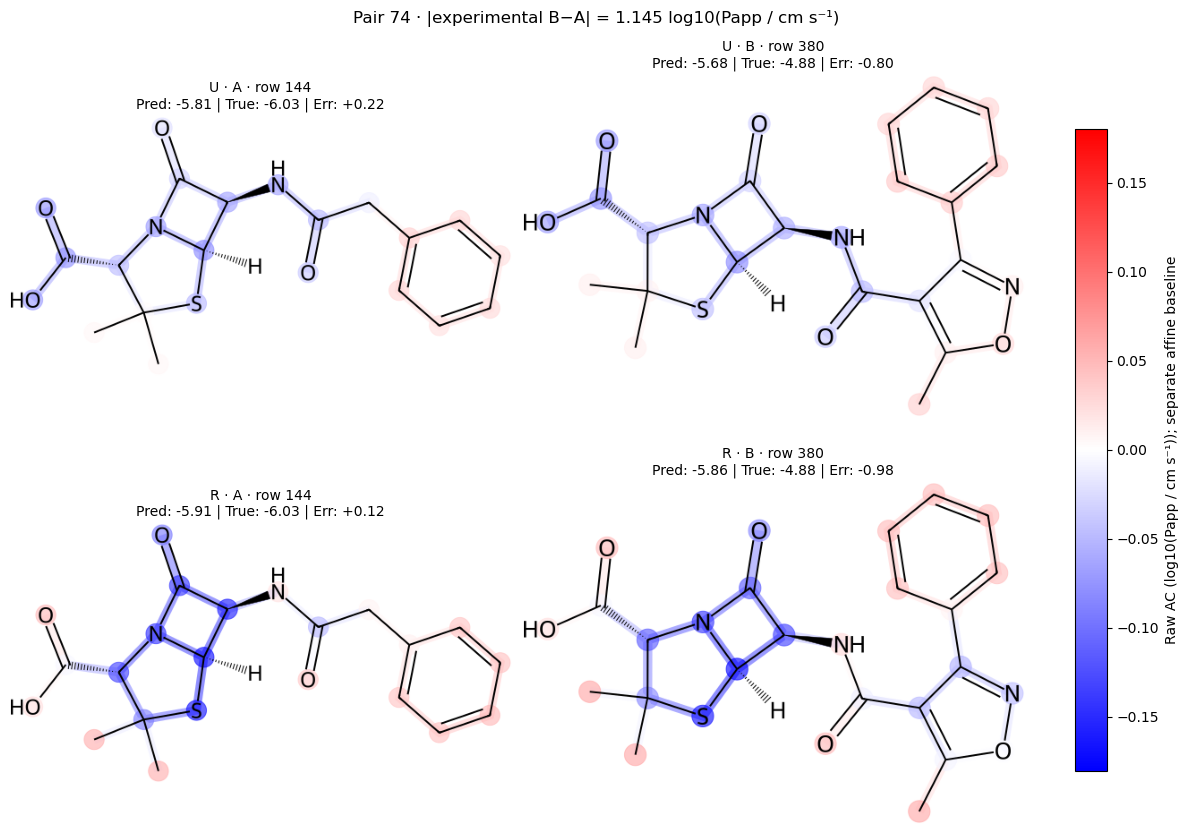

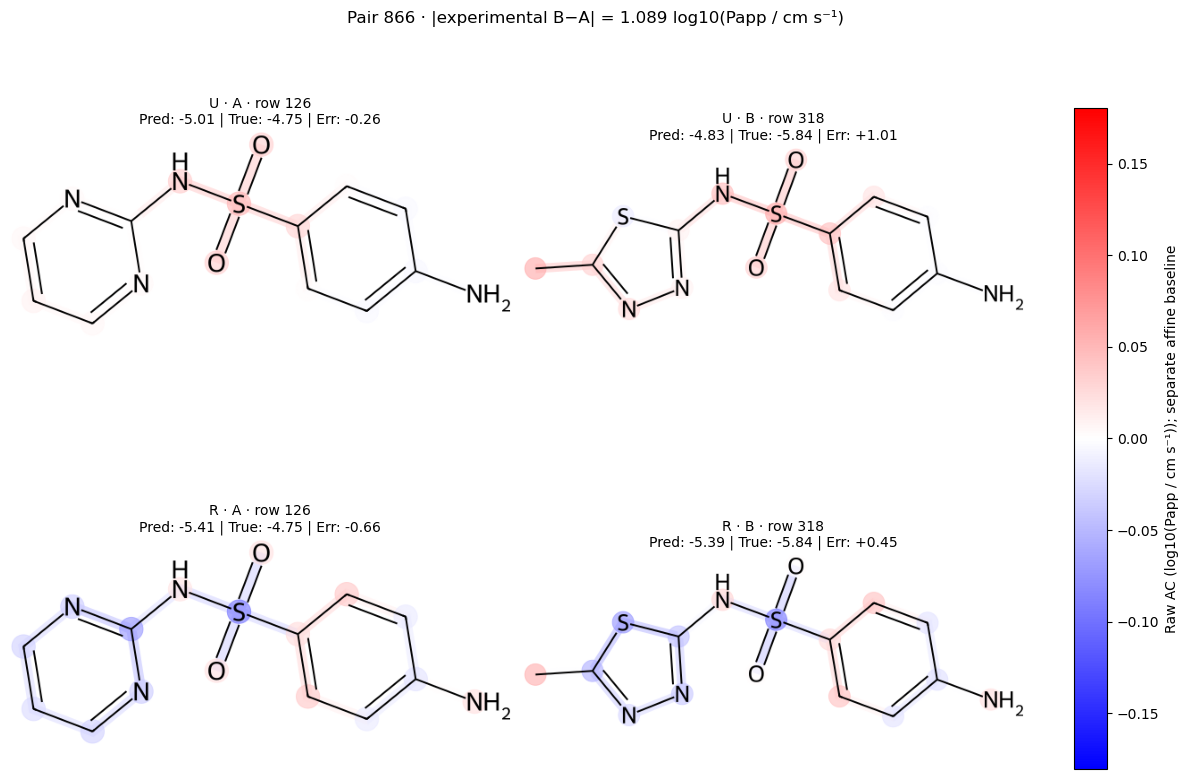

In [13]:
from xai_chem.plotting import plot_mmp_condition_comparison
# A single raw scale covers both conditions and every selected molecule.
selected_graph_ids = set(selected_pairs["i_id"]) | set(selected_pairs["j_id"])
shared_limit = max(float(result.atom_contributions.loc[
    result.atom_contributions["source_row_index"].isin(selected_graph_ids),
    "atom_contribution_raw"].abs().max()) for result in completed.values())
print({"shared_raw_ac_symmetric_limit": shared_limit, "raw_ac_units": TARGET_UNITS,
       "atom_indices_displayed": False})
for pair in selected_pairs.itertuples(index=False):
    figure, molecule_audit, atom_audit = plot_mmp_condition_comparison(
        completed, source_rows=[pair.i_id, pair.j_id], symmetric_limit=shared_limit,
        unit_label=TARGET_UNITS,
    )
    figure.suptitle(f"Pair {pair.pair_id} · |experimental B−A| = {pair.abs_target_difference:.3f} {TARGET_UNITS}")
    save_publication_figure(figure, run_root / "vis" / f"pair_{pair.pair_id}_UR_2x2.png")
    molecule_audit.to_csv(run_root / f"pair_{pair.pair_id}_map_audit.csv", index=False)
    atom_audit.to_csv(run_root / f"pair_{pair.pair_id}_raw_atom_values.csv", index=False)
    display(figure); plt.close(figure)


The raw maps describe model evidence; a shared scale makes U/R directly comparable.
Large observed gaps do not guarantee accurate predictions or chemically correct ACs.


## R-only reconstruction fidelity

These fits are in-sample on changed-region atoms. They do not measure unseen-atom prediction or causal attribution.

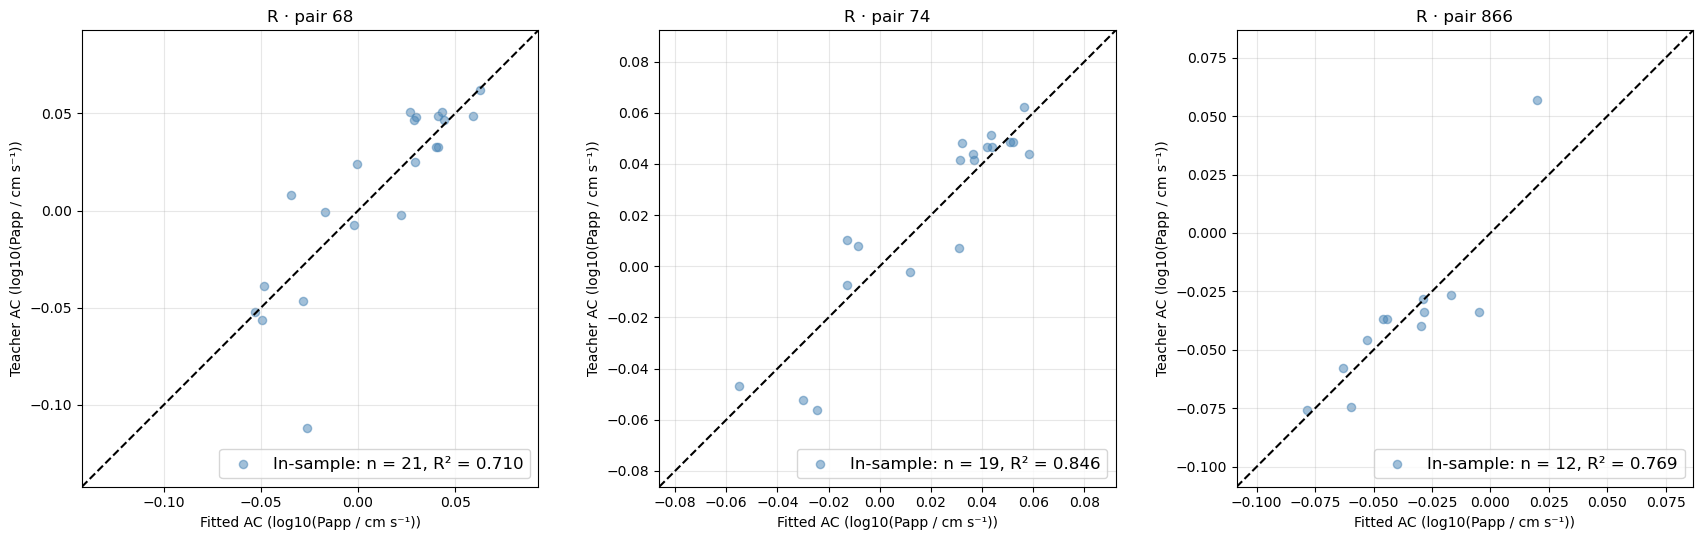

In [14]:
from xai_chem.plotting import plot_reconstruction_yy
# R-only surrogate fidelity: U/R comparison is reserved for the MMP maps.
figure, axes = plt.subplots(1, len(selected_pairs), figsize=(6 * len(selected_pairs), 5.5), squeeze=False)
for axis, pair in zip(axes[0], selected_pairs.itertuples(index=False)):
    fitted = fitted_pairs[pair.pair_id]
    plot_reconstruction_yy(fitted.atoms["atom_contribution"], fitted.atoms["prediction"],
        unit_label=f"AC ({TARGET_UNITS})", title=f"R · pair {pair.pair_id}", axis=axis)
figure.tight_layout()
save_publication_figure(figure, run_root / "vis" / "R_reconstruction_yy.png")
display(figure); plt.close(figure)


## 12. WISP: matched train/train and validation/validation pairs

Compute the official five metrics using i-minus-j differences. Divide atom-sum
gaps by one model-wide atom population SD (ddof=0), shared across its two splits.
Do not center or transform raw AC maps. Squared Pearson r is distinct from
regression R². Whole/prediction correlation is largely guaranteed by additivity;
variable-region agreement, constant-region dispersion, and direction accuracy
are the informative locality checks. Report raw constant-gap SD alongside the
normalized metric because U/R attribution scales can differ.

Definitions: [WISP](https://github.com/kerjans/ml-XAI),
[Janssen et al.](https://doi.org/10.1039/D5DD00398A).
These are explanation diagnostics, not comparisons against a separate WISP model.

In [15]:
from xai_chem.wisp import build_wisp_pair_table, summarize_official_wisp_metrics

wisp_rows = []
for label, result in completed.items():
    for split in ("train", "validation"):
        pairs, atom_std = build_wisp_pair_table(mmp, result.predictions, result.atom_contributions, split=split)
        pairs.to_csv(run_root / f"{label}_{split}_wisp_pairs.csv", index=False)
        metrics = summarize_official_wisp_metrics(pairs)
        wisp_rows.append({"condition": label, "split": split,
                          "atom_population_std_raw": atom_std,
                          "constant_gap_std_raw": float(np.std(pairs.constant_attribution_gap_raw, ddof=0)),
                          "max_pair_additivity_gap_raw": float(pairs.additivity_gap_raw.abs().max()), **metrics})
wisp_summary = pd.DataFrame(wisp_rows)
display(wisp_summary[["condition", "split", "n_pairs_evaluated",
    "variable_to_prediction_pearson_r_squared", "constant_attribution_gap_std",
    "constant_gap_std_raw", "variable_to_prediction_direction_accuracy"]].round(4))
wisp_summary.to_csv(run_root / "wisp_metrics.csv", index=False)
for split in ("train", "validation"):
    u_pairs = pd.read_csv(run_root / f"U_{split}_wisp_pairs.csv")
    r_pairs = pd.read_csv(run_root / f"R_{split}_wisp_pairs.csv")
    if not u_pairs[["pair_id", "i_id", "j_id"]].equals(r_pairs[["pair_id", "i_id", "j_id"]]):
        raise ValueError("U/R WISP pair populations differ")

,condition,split,n_pairs_evaluated,variable_to_prediction_pearson_r_squared,constant_attribution_gap_std,constant_gap_std_raw,variable_to_prediction_direction_accuracy
0,U,train,392,0.7090,5.0277,0.2386,0.8495
1,U,validation,35,0.8776,2.4355,0.1156,0.8571
2,R,train,392,0.8352,2.5301,0.1562,0.8980
3,R,validation,35,0.8364,1.3609,0.0840,0.9714


## Descriptor interpretation of one selected MMP

The first selected pair is used without inspecting fidelity. Rank descriptors by the absolute signed contribution to reconstructed changed-region B−A; the shared atom bias is reported separately. Correlated descriptors can share evidence, so ranks are descriptive.
Use the [seven-descriptor reading guide](../notebooks_for_sglt2/02_reconstruction.ipynb) to connect the ranked effects to conformational motion, local charge response, and nonbonded character. Positive/negative B−A effects raise/lower B's reconstructed changed-region AC sum relative to A; raw map colors show descriptor values, not beneficial/adverse effects. Higher log10(Papp) means greater permeability.


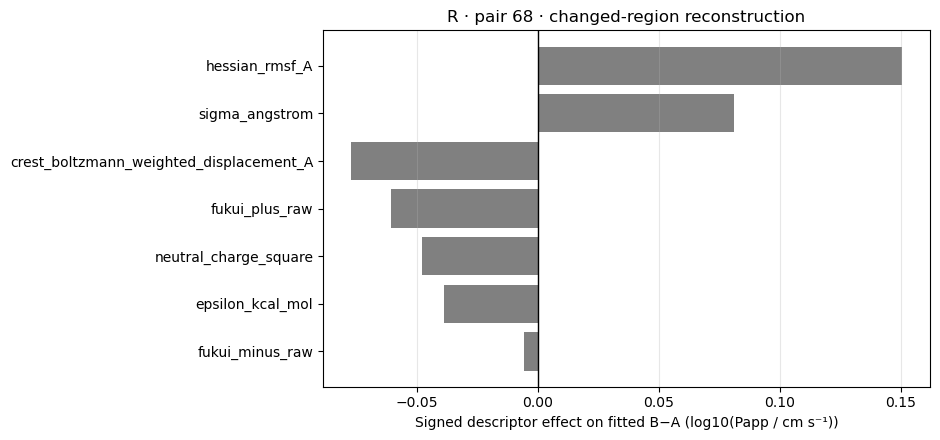

{'top_two_descriptors': ['hessian_rmsf_A', 'sigma_angstrom'], 'shared_atom_bias_B_minus_A': 0.029908367840107503, 'reconstructed_changed_region_B_minus_A': 0.031634532135769534}


In [16]:
# Use the first selected MMP as a declared example; do not select by fit quality.
example_pair = next(selected_pairs.itertuples(index=False))
fitted = fitted_pairs[example_pair.pair_id]
effects = fitted.concept_totals.drop_duplicates("concept").set_index("concept")["B_minus_A"]
descriptor_effects = effects.loc[list(PAPER_DESCRIPTORS)]
# Rank pair-difference effects, not coefficients or arbitrary display contrast.
ranking = descriptor_effects.rename("effect_B_minus_A").rename_axis("descriptor").reset_index()
ranking["absolute_effect"] = ranking["effect_B_minus_A"].abs()
ranking = ranking.sort_values(["absolute_effect", "descriptor"], ascending=[False, True], kind="stable")
top_descriptors = ranking.head(2)["descriptor"].tolist()
ranking.to_csv(run_root / f"R_pair_{example_pair.pair_id}_descriptor_ranking.csv", index=False)
figure, axis = plt.subplots(figsize=(9.5, 4.5))
axis.barh(ranking["descriptor"], ranking["effect_B_minus_A"], color="0.5")
axis.invert_yaxis(); axis.axvline(0, color="black", linewidth=1)
axis.set(xlabel=f"Signed descriptor effect on fitted B−A ({TARGET_UNITS})",
         title=f"R · pair {example_pair.pair_id} · changed-region reconstruction")
axis.grid(axis="x", alpha=0.3)
figure.tight_layout()
save_publication_figure(figure, run_root / "vis" / "R_descriptor_effects.png")
display(figure); plt.close(figure)
print({"top_two_descriptors": top_descriptors,
       "shared_atom_bias_B_minus_A": float(effects.loc["shared atom bias"]),
       "reconstructed_changed_region_B_minus_A": float(effects.sum())})


### Atom maps: R AC, highest-ranked descriptor, second-ranked descriptor

Rows are A/B molecules; columns are AC and two raw descriptors. Descriptor halos cover **all heavy atoms, including the shared core**; each value averages the atom and its bonded hydrogens. The surrogate is fitted only to changed-region atoms: core colors provide chemical context, not fitted core effects. Each descriptor retains one raw range shared across the supplied MMP endpoints and the established gist_rainbow palette. Read the colorbars; color order is not a perceptually uniform magnitude scale.


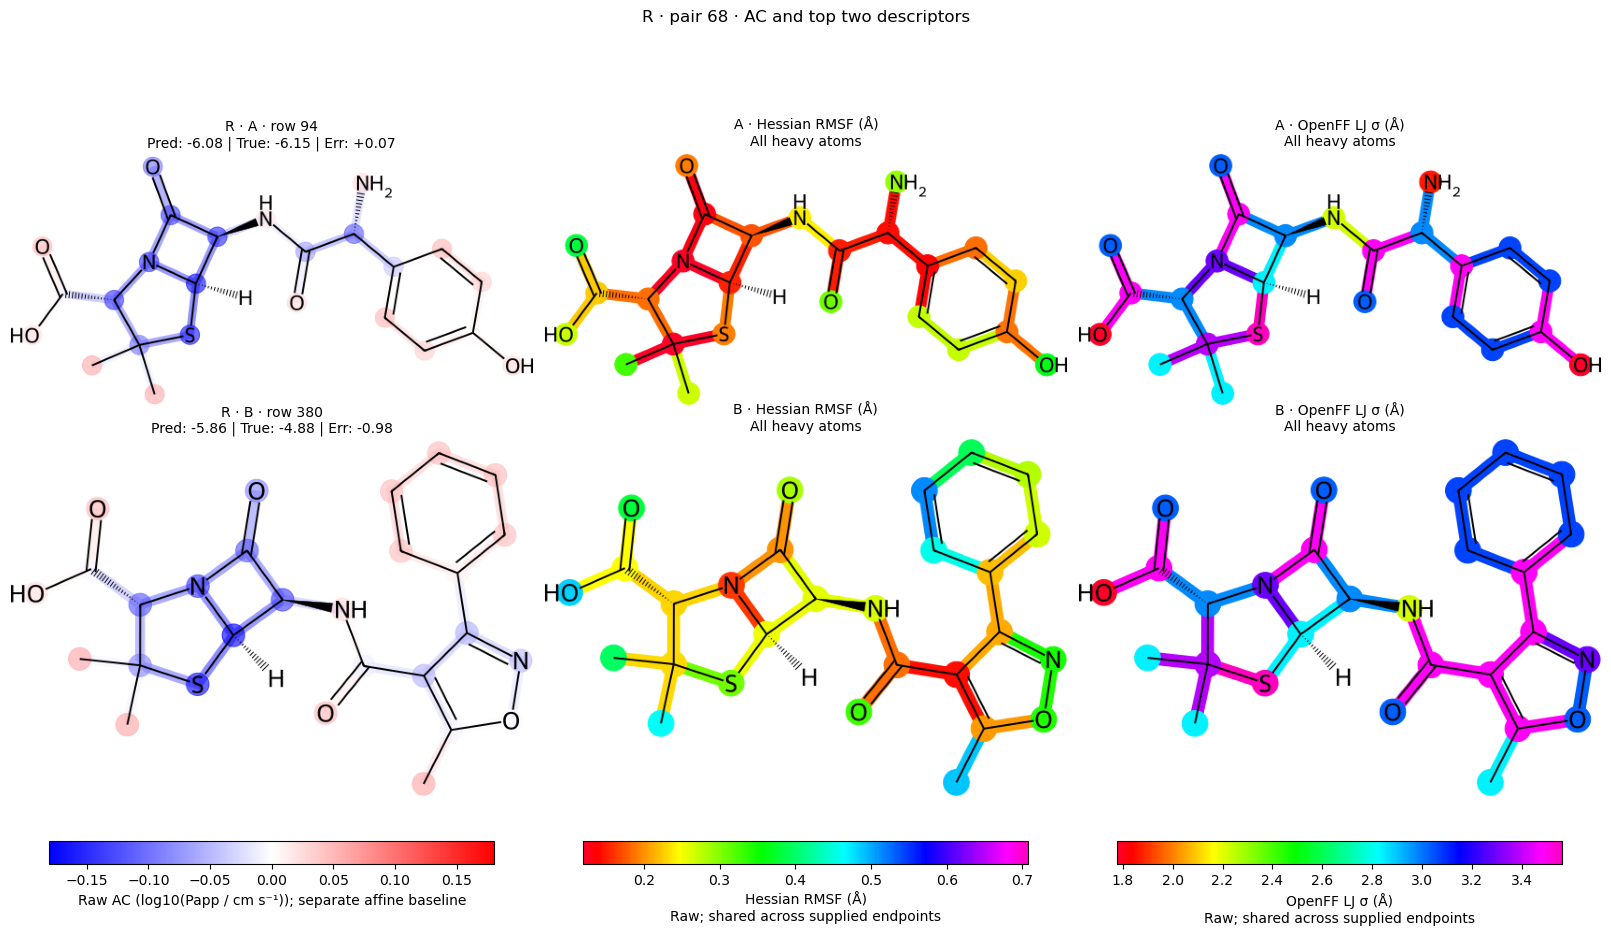

In [10]:
from xai_chem.plotting import plot_pair_descriptor_maps
# Map raw descriptor values across the whole molecule, including the shared core.
figure, descriptor_map_audit = plot_pair_descriptor_maps(
    completed["R"], descriptors,
    source_rows=[example_pair.i_id, example_pair.j_id], top_descriptors=top_descriptors,
    symmetric_limit=shared_limit, unit_label=TARGET_UNITS,
)
figure.suptitle(f"R · pair {example_pair.pair_id} · AC and top two descriptors")
save_publication_figure(figure, run_root / "vis" / "R_AC_top_descriptors_2x3.png")
descriptor_map_audit.to_csv(run_root / "descriptor_map_atom_values.csv", index=False)
display(figure); plt.close(figure)


The whole-molecule maps provide physical context for the changed-region surrogate. Core descriptor values were not fitted. These maps describe model-derived quantities and do not establish causal atomic effects.


The experiment establishes measured behavior for this split and settings only.
A lower regularization penalty is not evidence of physically correct ACs.
Ridge fidelity is in-sample reconstruction, not prediction on unseen atoms.
The supplied endpoint is preserved. Fragment positivity remains a model-design
assumption that needs endpoint-specific scrutiny.
